# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту
Студентка групи ШІ-31, Андрусишин Соломія



**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [1]:
STUDENT_NAME = 'Андрусишин Соломія Володимирівна'    
LIST_NUMBER  = 1    

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 1: Львів, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

встановлюю: osmnx, geopandas, shapely, pyproj, folium, mapclassify, h3, networkx ...
усі пакети на місці


In [ ]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas 
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [4]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_львів


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [5]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [6]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

   
    t0 = time.time()
    b0 = cache_bytes()

    g = getter()
    g = clean(g)
    g.to_parquet(path, index=False)

    COST[name] = {
        'спосіб': 'живий запит',
        'записів': len(g),
        'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
        'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
        'секунд': round(time.time() - t0, 3)
    }

    return g



In [11]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 148.4 км²


In [12]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 50603 | ребер 145118


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [13]:
display(pd.DataFrame(COST).T)

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.028,0.327
heritage,знімок,726,0.0,0.22,0.148
stations,знімок,26,0.0,0.045,0.038
amenities,знімок,1311,0.0,0.192,0.075
мережа walk,знімок,195721,0.0,10.076,1.203


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

Було порівняно два способи отримання географічних даних: живий запит через Overpass API та читання локального знімка GeoParquet. На прикладі пішохідної мережі Львова читання знімка виявилося приблизно у 133,5 раза швидшим. При повторному запуску всі дані зчитувалися з локальних файлів, що дозволило уникнути передачі 23,171 МБ через мережу. Таким чином, кешування підвищує швидкість і зменшує навантаження на сервер.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [14]:

mask = (
    heritage['historic'].notna() |
    heritage['tourism'].isin(TOURISM_OK)
)

has_name = heritage['name'].notna() & (
    heritage['name'].astype('string').str.strip().ne('').fillna(False)
)

cand = heritage[mask & has_name]

cand = cand.reset_index(drop=True)

print('Усього у шарі heritage:', len(heritage))
print('Підходять за тегами:', mask.sum())
print('З них мають name:', len(cand))
print('Відкинуто:', len(heritage) - len(cand))


Усього у шарі heritage: 726
Підходять за тегами: 726
З них мають name: 540
Відкинуто: 186


In [15]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial         174
tomb              53
wayside_cross     38
yes               21
house             18
vehicle           13
monument          12
ruins             10
railway_car       10
railway            7

=== tourism ===
tourism
museum        51
artwork       50
attraction    47
viewpoint      6
gallery        5

типи геометрії: {'Point': 421, 'Polygon': 111, 'LineString': 8}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

На другому етапі лабораторної роботи було проаналізовано 726 історичних і туристичних об'єктів Львова. Усі 726 об'єктів відповідали заданим категоріям тегів `historic` або `tourism`.
Після перевірки наявності назви (`name`) було залишено 540 об'єктів, а 186 відкинуто через відсутність назви.
Таким чином, ми виключили безіменні об'єкти, які складно однозначно ідентифікувати та використовувати для побудови туристичного маршруту. Проте такий фільтр може виключити й справді цінні пам'ятки, тому його обмеження необхідно пояснити замовнику.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [16]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

wiki_cols = [c for c in ['wikidata', 'wikipedia']
             if c in cand.columns]

cand['wiki'] = (
    cand[wiki_cols].notna().any(axis=1).astype(int)
    if wiki_cols else 0
)

lang_cols = [c for c in cand.columns if c.startswith('name:')]

cand['n_lang'] = cand[lang_cols].notna().sum(axis=1)

lang_score = cand['n_lang'].rank(pct=True)

museum_score = cand['tourism'].isin(
    ['museum', 'gallery']
).astype(int)

historic_score = cand['historic'].notna().astype(int)

cand['score'] = (
    0.40 * cand['wiki'] +
    0.30 * lang_score +
    0.20 * museum_score +
    0.10 * historic_score
)

print('Кандидатів:', len(cand))
print('Мають wiki:', int(cand['wiki'].sum()))

display(cand.nlargest(10, 'score')[
    ['name', 'wiki', 'n_lang', 'score']
])


Кандидатів: 540
Мають wiki: 97


,name,wiki,n_lang,score
453,Палац Потоцьких,1,6,0.998056
55,"Національний музей ""Тюрма на Лонцького""",1,6,0.898056
421,Національний музей у Львові,1,6,0.898056
430,Кам'яниця Корнякта,1,6,0.898056
440,Королівський арсенал,1,6,0.898056
54,Музей пивоваріння,1,5,0.892222
180,Музей міста,1,5,0.892222
422,Львівський музей історії релігії,1,5,0.892222
424,Львівський Державний Природознавчий Музей,1,5,0.892222
432,"Арсенал, Львівський державний історичний музей...",1,5,0.892222


### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [17]:

N_SMALL, N_LARGE = 10, 30

ranked_score = cand.nlargest(N_LARGE, 'score')

top_score = ranked_score.reset_index(drop=True)

top10 = top_score.head(N_SMALL)

ranked_area = cand.nlargest(N_SMALL, 'area_m2')
top_naive = ranked_area.reset_index(drop=True)

overlap = len(
    set(ranked_score.head(N_SMALL).index)
    & set(ranked_area.index)
)

print('Перетин: %d з %d' % (overlap, N_SMALL))

display(pd.DataFrame({
    'За нашим критерієм': list(top10['name']),
    'За площею': list(top_naive['name'])
}))


Перетин: 2 з 10


,За нашим критерієм,За площею
0,Палац Потоцьких,Личаківський цвинтар
1,"Національний музей ""Тюрма на Лонцького""",Марсове поле
2,Національний музей у Львові,Меморіал львівських орлят
3,Кам'яниця Корнякта,"Австрійський форт (Fort ""Zjawienska Gora"")"
4,Королівський арсенал,Меморіал Українським Січовим стрільцям та воїн...
5,Музей пивоваріння,Австрійський форт
6,Музей міста,Львівський музей історії релігії
7,Львівський музей історії релігії,Національний музей у Львові
8,Львівський Державний Природознавчий Музей,Польський військовий меморіал
9,"Арсенал, Львівський державний історичний музей...",Будинок вчених


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [18]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])


pairs = close_pairs(top_score, 60)

print('Знайдено близьких пар:', len(pairs))

for i, j, distance in pairs:
    name1 = top_score.iloc[i]['name']
    name2 = top_score.iloc[j]['name']

    print(f'{name1} <-> {name2}: {distance:.1f} м')


Знайдено близьких пар: 6
Львівський історичний музей <-> Музей скла: 20.2 м
Кам'яниця Корнякта <-> Львівський історичний музей: 26.0 м
Кам'яниця Корнякта <-> Музей скла: 44.3 м
Музей міста <-> Львівський історичний музей: 50.5 м
Музей Михайла Грушевського <-> Музей Івана Франка: 55.8 м
Палац Потоцьких <-> Музей мистецтва давньої української книги: 58.8 м


Висновок: У цьому розділі було розроблено власний рейтинг історико-культурних пам'яток Львова на основі чотирьох критеріїв: наявності статті у Wikipedia або Wikidata (40%), кількості перекладів назви (30%), належності до музеїв чи галерей (20%) та наявності історичного тегу (10%). Усі показники було приведено до спільної шкали від 0 до 1.
Із 540 кандидатів 97 мали посилання на Wikipedia або Wikidata. Найвищий рейтинг отримав Палац Потоцьких із результатом 0,9981.
Для порівняння було побудовано альтернативний рейтинг за площею об'єктів. У двох списках топ-10 збіглися лише 2 пам'ятки, тобто 20%. Це показує, що поняття «найкращі» залежить від обраних критеріїв оцінювання.
Також серед 30 найкращих об'єктів було знайдено 6 пар, розташованих ближче ніж 60 метрів одна від одної. Оскільки близьке розташування не обов'язково означає дублювання, було вирішено не видаляти об'єкти автоматично без додаткової перевірки.
Отже, головний висновок полягає в тому, що якість рейтингу залежить не лише від початкових даних, а й від обґрунтованості обраних критеріїв, їхніх ваг та правильності обробки можливих дублікатів.

---
## 4. Старт: вокзал, і прив'язка точок до графа

In [19]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 26
                 name  railway building
0               Рудно  station      NaN
1            5-й Парк     halt      NaN
2    Львів-Коновальця     halt      NaN
3   Львів-Персенківка  station      NaN
4          Зубрівська     halt      NaN
5             Сонячна  station      NaN
6             Паркова  station      NaN
7      Львів-Клепарів  station      NaN
8       Княгині Ольги     halt      NaN
9    Львів-Городоцька     halt      NaN
10              Рясна     halt      NaN
11            Скнилів  station      NaN


In [24]:

station = stations[
    stations['name'] == 'Головний вокзал'
].copy()

print('Старт:', station['name'].iloc[0])


Старт: Головний вокзал


In [25]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 50603 вузлів, 143741 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [26]:

def check_snap(points, ids, dist, label):

    n_points = len(points)

    n_unique = len(set(ids))

    print(f'--- {label} ---')
    print(f'Кількість точок: {n_points}')
    print(f'Різних вузлів: {n_unique}')

    print(f'Медіана відстані: {np.median(dist):.2f} м')
    print(f'Максимальна відстань: {np.max(dist):.2f} м')

    if n_unique < n_points:
        print('Увага! Деякі точки злиплися:')

        for node_id in set(ids):
            indices = np.where(ids == node_id)[0]

            if len(indices) > 1:
                names = points['name'].iloc[indices].tolist()
                print(f'Вузол {node_id}: {names}')

    else:
        print('Усі точки прив’язані до різних вузлів.')


In [27]:
points10 = make_points(top10)

ids10, dist10 = snap(points10)

check_snap(points10, ids10, dist10, 'Топ-10')

--- Топ-10 ---
Кількість точок: 11
Різних вузлів: 11
Медіана відстані: 22.94 м
Максимальна відстань: 47.24 м
Усі точки прив’язані до різних вузлів.


Висновок: У четвертому розділі було вибрано головний залізничний вокзал Львова як початкову та кінцеву точку туристичного маршруту. На основі даних OpenStreetMap побудовано орієнтований граф пішохідної мережі, що містить 50 603 вузли та 143 741 ребро.
Було виконано прив'язку 10 найкращих пам'яток і вокзалу до найближчих вузлів графа. Перевірка показала, що всі 11 точок відповідають 11 різним вузлам, тобто злипання не виявлено.
Медіанна відстань від об'єкта до найближчого вузла становила 22,94 м, а максимальна — 47,24 м.
Отже, прив'язка виконана коректно за перевіреними показниками, і отримані вузли можна використовувати для подальшого розрахунку відстаней та побудови туристичного маршруту.

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [29]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D


def straight_matrix(points):
    p = points.to_crs(32635)
    XY = np.c_[p.geometry.x.values, p.geometry.y.values]
    diff = XY[:, None, :] - XY[None, :, :]
    E = np.sqrt((diff ** 2).sum(axis=2))
    np.fill_diagonal(E, 0.0)
    return E



def detour_factor(D, E):
    mask = np.isfinite(D) & np.isfinite(E) & (E > 0)
    ratios = D[mask] / E[mask]
    return float(np.median(ratios)) if len(ratios) else np.nan



**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [30]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

--- мала задача ---
Кількість точок: 11
Різних вузлів: 11
Медіана відстані: 22.94 м
Максимальна відстань: 47.24 м
Усі точки прив’язані до різних вузлів.
матриця за 4.788 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.20


Висновок: У п'ятому розділі було побудовано дві матриці віддалей для 11 туристичних точок Львова: матрицю прямих евклідових відстаней та матрицю найкоротших шляхів пішохідною мережею за алгоритмом Дейкстри.
Час обчислення мережевої матриці становив 4,788 секунди. Недосяжних пар не виявлено, що підтверджує наявність шляхів між усіма вибраними точками.
Максимальна асиметрія становила 0 метрів, тобто найкоротші відстані в обох напрямках однакові.
Медіанний коефіцієнт обходу дорівнює 1,20. Це означає, що реальні пішохідні відстані зазвичай приблизно на 20% більші за прямі. Отриманий результат відповідає типовому діапазону для міської пішохідної мережі.
Отже, для побудови реалістичного туристичного маршруту необхідно використовувати мережеві відстані, оскільки евклідові відстані не враховують розташування вулиць, будівель та інших перешкод.

> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [31]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))


def nearest_neighbour(D):
    n = len(D)

    tour = [0]
    unvisited = set(range(1, n))
    current = 0

    while unvisited:
        next_point = min(
            unvisited,
            key=lambda j: D[current, j]
        )

        tour.append(next_point)
        unvisited.remove(next_point)
        current = next_point

    tour.append(0)

    return tour



def two_opt(D, tour):
    best = tour.copy()
    improved = True

    while improved:
        improved = False

        for i in range(1, len(best) - 2):
            for j in range(i + 1, len(best) - 1):

                new_tour = (
                    best[:i] +
                    best[i:j + 1][::-1] +
                    best[j + 1:]
                )

                if tour_length(D, new_tour) < tour_length(D, best) - 1e-9:
                    best = new_tour
                    improved = True

    return best


In [32]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [33]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [34]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,8716,1.96
2-opt,8548,0.00
Held-Karp (точний),8548,0.00



оптимальний порядок:
   0. СТАРТ: Головний вокзал
   1. Музей пивоваріння
   2. Національний музей у Львові
   3. Львівський Державний Природознавчий Музей
   4. Музей міста
   5. Кам'яниця Корнякта
   6. Львівський музей історії релігії
   7. Королівський арсенал
   8. Арсенал, Львівський державний історичний музей старовинної зброї
   9. Палац Потоцьких
  10. Національний музей "Тюрма на Лонцького"
  11. СТАРТ: Головний вокзал

довжина: 8.55 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [35]:

rows = []

for n in [11, 16, 21, 26, 31]:
    cells = 2 ** (n - 1) * (n - 1)
    memory_gb = cells * 8 / 1e9

    rows.append({
        'Кількість точок': n,
        'Кількість клітинок': cells,
        'Памʼять, ГБ': round(memory_gb, 4)
    })

display(pd.DataFrame(rows))


,Кількість точок,Кількість клітинок,"Памʼять, ГБ"
0,11,10240,0.0001
1,16,491520,0.0039
2,21,20971520,0.1678
3,26,838860800,6.7109
4,31,32212254720,257.6980


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

In [36]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

--- велика задача ---
Кількість точок: 31
Різних вузлів: 30
Медіана відстані: 18.11 м
Максимальна відстань: 47.24 м
Увага! Деякі точки злиплися:
Вузол 13803598476: ["Кам'яниця Корнякта", 'Львівський історичний музей']
коефіцієнт обходу: 1.21
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    24729 м
2-opt            :    22495 м  за 0.032 с  (коротше на 9.0%)

ЦЕ — база порівняння для лабораторної роботи № 8.


Висновок: Під час виконання великої задачі було виявлено проблему прив'язки географічних об'єктів до пішохідного графа. Із 31 точки (30 пам'яток і вокзал) було отримано 30 різних вузлів.
Кам'яниця Корнякта та Львівський історичний музей прив'язалися до одного вузла, хоча відстань між їхніми географічними точками становить 25,68 м.
Унаслідок цього матриця мережевих віддалей визначає відстань між ними як 0 м. Це є обмеженням методу прив'язки до найближчого вузла, а не свідченням фактичної відсутності відстані між об'єктами.
Було прийнято рішення залишити початкові дані без змін, зафіксувавши виявлену неточність. У реальному туристичному застосунку для підвищення точності маршруту необхідно додатково враховувати розташування входів та з'єднання об'єктів із пішохідною мережею.

---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м


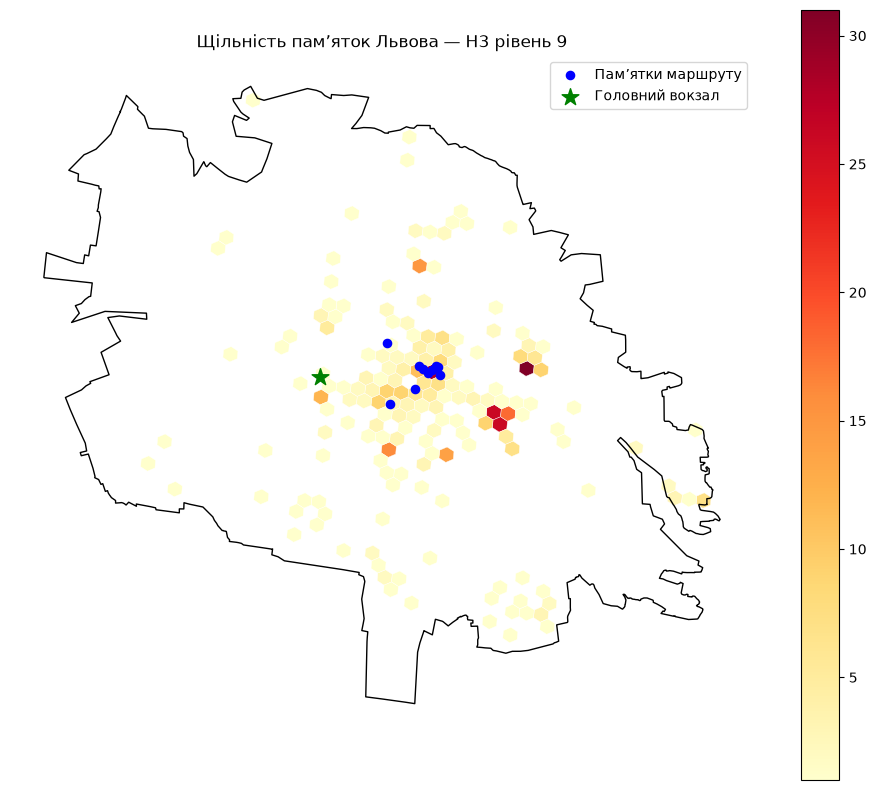

Усього памʼяток: 540
Зайнятих H3-комірок: 172
Максимум памʼяток у комірці: 31


In [39]:
import h3
from shapely.geometry import Polygon
import matplotlib.pyplot as plt

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

cand_points = cand.to_crs(4326).geometry.representative_point()

cand['h3'] = [
    h3.latlng_to_cell(p.y, p.x, H3_RES)
    for p in cand_points
]

dens = (
    cand.groupby('h3')
    .size()
    .reset_index(name='count')
    .sort_values('count', ascending=False)
    .reset_index(drop=True)
)

hexes = gpd.GeoDataFrame(
    dens,
    geometry=[
        Polygon([
            (lon, lat)
            for lat, lon in h3.cell_to_boundary(cell)
        ])
        for cell in dens['h3']
    ],
    crs='EPSG:4326'
)

fig, ax = plt.subplots(figsize=(12, 10))

hexes.to_crs(32635).plot(
    ax=ax,
    column='count',
    cmap='YlOrRd',
    legend=True,
    edgecolor='white',
    linewidth=0.3
)

boundary.to_crs(32635).boundary.plot(
    ax=ax, color='black', linewidth=1
)

pts10.iloc[1:].to_crs(32635).plot(
    ax=ax, color='blue', markersize=35,
    label='Памʼятки маршруту'
)

pts10.iloc[[0]].to_crs(32635).plot(
    ax=ax, color='green', marker='*',
    markersize=160, label='Головний вокзал'
)

ax.set_title('Щільність памʼяток Львова — H3 рівень 9')
ax.legend()
ax.set_axis_off()

plt.show()

print('Усього памʼяток:', len(cand))
print('Зайнятих H3-комірок:', len(dens))
print('Максимум памʼяток у комірці:', dens['count'].max())


In [40]:
print((dens['count'].sort_values(ascending=False).cumsum() < 270).sum() + 1)

19


> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

Висновок: У сьомому розділі було виконано просторову індексацію 540 історико-культурних об'єктів Львова за допомогою H3 рівня 9 із середньою довжиною ребра комірки 201 м.
Пам'ятки розподілилися між 172 комірками, причому максимальна кількість в одній комірці становила 31 об'єкт.
Аналіз показав, що половина всіх пам'яток (270) зосереджена лише у 19 комірках, тобто приблизно 11% зайнятих комірок.
Це свідчить про нерівномірне розміщення туристичних об'єктів і значну їх концентрацію в центральній частині Львова. Відповідно, туристичний маршрут доцільно формувати з компактним обходом центральної частини міста та переходами до окремих віддалених пам'яток.

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [41]:

pts_m = pts10[['name', 'geometry']].copy().to_crs(32635)
pts_m = pts_m.rename(columns={'name': 'Точка маршруту'})

amen_m = amenities[['name', 'amenity', 'geometry']].copy().to_crs(32635)
amen_m = amen_m.rename(columns={'name': 'Заклад'})

nearest = gpd.sjoin_nearest(
    pts_m,
    amen_m,
    how='left',
    distance_col='Відстань_м'
)

nearest = nearest.sort_values('Відстань_м')
nearest = nearest[~nearest.index.duplicated(keep='first')]
nearest = nearest.sort_index()

result = nearest[
    ['Точка маршруту', 'Заклад', 'amenity', 'Відстань_м']
].copy()

result['Заклад'] = result['Заклад'].fillna('Без назви')
result['Відстань_м'] = result['Відстань_м'].round(2)

display(result.reset_index(drop=True))


,Точка маршруту,Заклад,amenity,Відстань_м
0,СТАРТ: Головний вокзал,Експрес,cafe,83.22
1,Палац Потоцьких,Корівка,restaurant,80.34
2,"Національний музей ""Тюрма на Лонцького""",PamPuh,cafe,65.37
3,Національний музей у Львові,Da Vinci,restaurant,50.77
4,Кам'яниця Корнякта,П'яте підземелля,restaurant,16.90
5,Королівський арсенал,Без назви,toilets,37.68
6,Музей пивоваріння,Robert Doms,restaurant,53.33
7,Музей міста,Без назви,drinking_water,11.64
8,Львівський музей історії релігії,Cold comfort,cafe,19.52
9,Львівський Державний Природознавчий Музей,Божевільний будинок,restaurant,39.71


Висновок: У восьмому розділі було виконано просторове поєднання туристичних точок Львова із шаром закладів amenities за допомогою функції sjoin_nearest() бібліотеки GeoPandas.
Для кожної з 11 точок маршруту знайдено найближчий заклад та визначено відстань до нього в метрах. Для забезпечення правильності обчислень обидва набори географічних даних було переведено в метричну систему координат EPSG:32635.

---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [ ]:


node_xy = nodes.set_index('osmid')[['x', 'y']]

edges_best = (
    edges.sort_values('length')
    .drop_duplicates(subset=['u', 'v'])
)

edge_geom = {
    (r.u, r.v): r.geometry
    for r in edges_best.itertuples(index=False)
}

def route_coords(tour, ids):
    coords = []

    for a, b in zip(tour[:-1], tour[1:]):
        path = nx.shortest_path(
            G, ids[a], ids[b], weight='length'
        )

        for u, v in zip(path[:-1], path[1:]):
            geom = edge_geom[(u, v)]

            if geom is not None and geom.geom_type == 'LineString':
                xy = list(geom.coords)
            else:
                xy = [
                    (node_xy.loc[u, 'x'], node_xy.loc[u, 'y']),
                    (node_xy.loc[v, 'x'], node_xy.loc[v, 'y'])
                ]
            ux, uy = node_xy.loc[u, ['x', 'y']]
            if ((xy[-1][0] - ux)**2 + (xy[-1][1] - uy)**2 <
                (xy[0][0] - ux)**2 + (xy[0][1] - uy)**2):
                xy.reverse()

            segment = [(float(y), float(x)) for x, y in xy]

            if coords and coords[-1] == segment[0]:
                coords.extend(segment[1:])
            else:
                coords.extend(segment)

    return coords

fmap = folium.Map(
    location=[
        pts10.geometry.y.mean(),
        pts10.geometry.x.mean()
    ],
    zoom_start=13,
    tiles=BASEMAP
)

real_route = route_coords(ex10, ids10)

folium.PolyLine(
    real_route,
    color='blue',
    weight=5,
    opacity=0.85,
    tooltip='Реальний пішохідний маршрут'
).add_to(fmap)


straight_route = [
    (
        float(pts10.geometry.iloc[i].y),
        float(pts10.geometry.iloc[i].x)
    )
    for i in ex10
]

folium.PolyLine(
    straight_route,
    color='red',
    weight=3,
    opacity=0.8,
    dash_array='8, 6',
    tooltip='Відстані по прямій'
).add_to(fmap)


for step, i in enumerate(ex10[:-1]):
    point = pts10.geometry.iloc[i]
    name = str(pts10['name'].iloc[i])

    folium.Marker(
        location=[point.y, point.x],
        popup=f'{step}. {name}',
        tooltip=name,
        icon=folium.DivIcon(
            html=f"""
            <div style="
                background: {'green' if step == 0 else '#2563eb'};
                color: white;
                border-radius: 50%;
                width: 26px;
                height: 26px;
                text-align: center;
                line-height: 26px;
                font-weight: bold;
                border: 2px solid white;
            ">{step}</div>
            """
        )
    ).add_to(fmap)


fmap.fit_bounds(real_route)

fmap.save('lr5_маршрут.html')



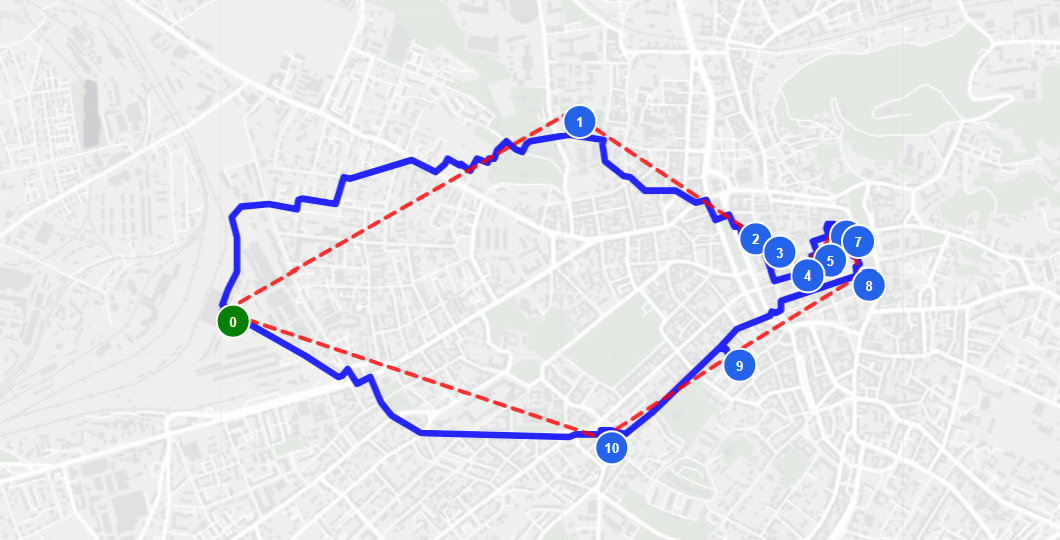

---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [44]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (17.5 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?

Із 726 історико-культурних об'єктів Львова було відкинуто 186 об'єктів, оскільки вони не мали заповненої назви (name). Для подальшого аналізу залишилося 540 кандидатів.
Я б не передавала цей фільтр замовнику без пояснень, оскільки серед безіменних об'єктів також можуть бути цінні пам'ятки. Тому необхідно зазначити, що відбір здійснювався за наявністю назви, а не за реальною історичною значущістю.

2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?

Для створення рейтингу використано чотири критерії:
40% — наявність статті у Wikipedia або Wikidata, що свідчить про певну впізнаваність об'єкта.
30% — кількість перекладів назви, яка може вказувати на міжнародний інтерес.
20% — належність до музеїв або галерей, оскільки ці об'єкти призначені для туристичного відвідування.
10% — наявність історичного тегу, що характеризує історичну природу об'єкта.
Кількість перекладів було нормалізовано за допомогою rank(pct=True), щоб показники мали порівнювану шкалу.
Найбільшу вагу надано зовнішній впізнаваності об'єкта, а найменшу — історичному тегу, оскільки його наявність не завжди означає високу туристичну цінність.

3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?

У двох рейтингах збіглися лише 2 об'єкти з 10 (20%).
Перший рейтинг враховував комплексні критерії туристичної значущості, а другий — площу географічних об'єктів.
Це показує, що поняття «найкращі» залежить від вибраного критерію. Великий за площею об'єкт не обов'язково є найціннішим для туриста. Тому аналітик повинен обґрунтовувати критерії оцінювання.

4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?

Отриманий медіанний коефіцієнт обходу становить 1,20, що відповідає нижній межі типового діапазону 1,2–1,6 для пішохідної мережі.
Це означає, що пішохідні відстані за медіанним співвідношенням приблизно на 20% довші за прямі.
Такий результат пояснюється особливостями міської мережі Львова, де значна частина вибраних пам'яток розташована в центральній частині міста з розгалуженою системою пішохідних вулиць.

5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?

Алгоритм найближчого сусіда побудував маршрут довжиною 8716 м, тоді як точний алгоритм Held–Karp знайшов оптимальний маршрут довжиною 8548 м.
Отже, найближчий сусід виявився гіршим на 1,96%, або 168 метрів.
Різниця виявилася досить невеликою, що дещо здивувало, адже жадібний алгоритм не гарантує оптимального результату. Алгоритм 2-opt зміг покращити маршрут до 8548 м, тобто досягти точного оптимуму для нашої малої задачі.

6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.

У великій задачі ми маємо 30 пам'яток і вокзал, тобто 31 точку.
Алгоритм Held–Karp використовує динамічне програмування, у якому кількість станів зростає експоненційно.
Для 31 точки потрібно:
32 212 254 720 клітинок таблиці;
приблизно 257,70 ГБ оперативної пам'яті за умови 8 байтів на клітинку.
Це перевищує можливості звичайного комп'ютера, причому фактичні витрати пам'яті реалізації можуть бути ще більшими.
Тому проблема полягає не лише у тривалості обчислень, а насамперед у надмірних вимогах до пам'яті.
Для великої задачі було застосовано наближені алгоритми. Найближчий сусід отримав маршрут довжиною 24 729 м, а 2-opt скоротив його до 22 495 м, тобто приблизно на 9%.

7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

Під час аналізу було виявлено кілька проблем якості даних OpenStreetMap.
По-перше, 186 об'єктів не мали назв, тому їх було виключено з подальшого рейтингу.
По-друге, серед 30 найкращих пам'яток знайдено 6 пар об'єктів, розташованих ближче ніж 60 метрів одна від одної. Однак близькість не обов'язково означає дублювання, тому об'єкти не видалялися автоматично.
По-третє, під час прив'язки великої задачі до пішохідного графа виявлено, що Кам'яниця Корнякта та Львівський історичний музей потрапили на один вузол, хоча відстань між їхніми географічними точками становить 25,68 м.
Через це матриця віддалей помилково визначає відстань між ними як 0 м. Було вирішено залишити початкову вибірку без змін, але зафіксувати цю неточність у звіті.
Отже, аналіз показав, що навіть за успішного виконання програми географічні дані можуть містити неточності, які необхідно окремо перевіряти й документувати.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [46]:
REPORT = '''
1.
2.
3.
4.
5.
6.
7.

Декларація про використання ШІ:
Під час виконання лабораторної роботи я використовувала ChatGPT переважно для допомоги з написанням складніших частин Python-коду та пояснення алгоритмів.
Отриманий код я запускала у VS Code та перевіряла результати відповідно до методичних вказівок. Для перевірки використовувала контрольні твердження assert, порівняння результатів алгоритмів із точним розв'язком Held–Karp, перевірку кількості вузлів, метричної системи координат та аналіз побудованих карт.
Також було окремо перевірено проблему прив'язки двох пам'яток до одного вузла графа, яку зафіксовано у звіті.
'''
print(REPORT)


1.
2.
3.
4.
5.
6.
7.

Декларація про використання ШІ:
Під час виконання лабораторної роботи я використовувала ChatGPT переважно для допомоги з написанням складніших частин Python-коду та пояснення алгоритмів.
Отриманий код я запускала у VS Code та перевіряла результати відповідно до методичних вказівок. Для перевірки використовувала контрольні твердження assert, порівняння результатів алгоритмів із точним розв'язком Held–Karp, перевірку кількості вузлів, метричної системи координат та аналіз побудованих карт.
Також було окремо перевірено проблему прив'язки двох пам'яток до одного вузла графа, яку зафіксовано у звіті.

